# 01 — Análisis exploratorio de datos (EDA)

**Proyecto:** Sistema inteligente de soporte a la decisión de riesgo de impago  
**Módulo:** preparación del terreno para el Módulo 1 (Aprendizaje Automático)

En este notebook vamos a:

1. Cargar el dataset UCI *Default of Credit Card Clients* (ID 350, licencia CC BY 4.0).
2. Entender la forma de los datos, la variable objetivo y el desbalance de clases.
3. Detectar duplicados, valores atípicos y variables que deben tratarse como categóricas.
4. Fijar una división entrenamiento/prueba **estratificada** y reproducible.

> **Idea clave para el informe:** si alrededor del 77 % de los clientes no impaga, un modelo que siempre diga «no impaga» ya tendría ~77 % de *accuracy*… y sería inútil. Por eso trabajaremos con **F1, recall y AUC-PR**, no solo con exactitud. Esta observación alimentará directamente la pregunta de reflexión del PDF.

Fuente: Yeh, I. (2009). *Default of Credit Card Clients* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H

In [1]:
from pathlib import Path
import sys

# Permitir importar src/ tanto si se ejecuta desde notebooks/ como desde la raíz.
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data_loader import RAW_CSV, describe, load_credit_default

RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (8, 4)

X, y = load_credit_default()
print("CSV local:", RAW_CSV.relative_to(ROOT))
describe(X, y)
X.head()

CSV local: data\raw\credit_default.csv
Forma de X: (30000, 23) | forma de y: (30000,)
 Variables: 23 -> LIMIT_BAL, SEX, EDUCATION, MARRIAGE, AGE, PAY_0, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6, BILL_AMT1, BILL_AMT2, BILL_AMT3, BILL_AMT4, BILL_AMT5, BILL_AMT6, PAY_AMT1, PAY_AMT2, PAY_AMT3, PAY_AMT4, PAY_AMT5, PAY_AMT6

Distribución de la clase objetivo:
default
pago (0)      23364
impago (1)     6636

Impago: 22.12%
Valores faltantes: 0

Tipos:
int64    23


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679


## 1. Forma y tipos de variables

`X` tiene 23 columnas numéricas. Aunque sean números, varias son **códigos categóricos**:

- `SEX` (1/2), `EDUCATION` (1..4), `MARRIAGE` (1..3).
- `PAY_0 … PAY_6`: `-1` = pago puntual; `1` = un mes de retraso; …; `9` = nueve o más meses.

Las trataremos con codificación *one-hot* dentro del pipeline. No las escalaremos como si fueran magnitudes continuas.

In [3]:
print("X.shape =", X.shape, "| y.shape =", y.shape)
print("\nColumnas:", list(X.columns))
print("\nPrimeras filas:")
X.head()

X.shape = (30000, 23) | y.shape = (30000,)

Columnas: ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

Primeras filas:


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679


## 2. Desbalance de clases y por qué el Accuracy engaña

La clase positiva es `impago (1)`. Calculemos el clasificador trivial «siempre predice pago (0)» y comparemos su *accuracy* con su capacidad real de detectar impagos.

,n,proporcion
pago (0),23364,0.7788
impago (1),6636,0.2212


Accuracy de 'siempre predecir pago': 77.88%
Recall para la clase impago: 0.00%  <-- detecta cero impagos


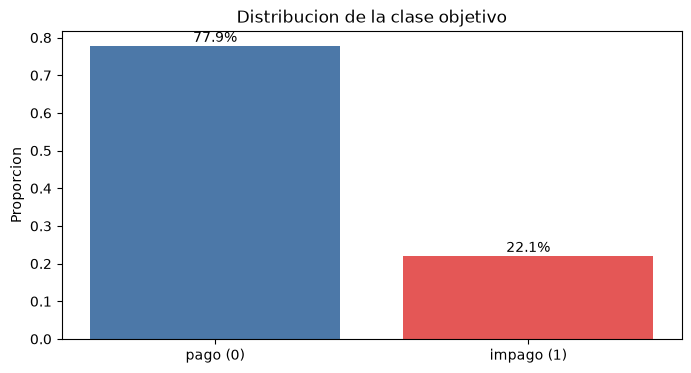

In [ ]:
counts = y.value_counts().sort_index()
rates = y.value_counts(normalize=True).sort_index()
resumen = pd.DataFrame({"n": counts, "proporcion": rates})
resumen.index = ["pago (0)", "impago (1)"]
display(resumen)

accuracy_trivial = (y == 0).mean()
print(f"Accuracy de 'siempre predecir pago': {accuracy_trivial:.2%}")
print("Recall para la clase impago: 0.00%  <-- detecta cero impagos")

fig, ax = plt.subplots()
ax.bar(resumen.index, resumen["proporcion"], color=["#4c78a8", "#e45756"])
ax.set_ylabel("Proporcion")
ax.set_title("Distribucion de la clase objetivo")
for i, v in enumerate(resumen["proporcion"]):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
plt.show()

## 3. Historial de pagos: la señal más interpretable

`PAY_0` es el estado de pago en septiembre de 2005 (el mes más reciente del dataset). Observemos cómo crece la tasa de impago a medida que aumenta el retraso previo. Esta gráfica será muy útil en la defensa para explicar el sistema difuso del Módulo 2.

default,pago,impago,n
PAY_0,,,
-2,0.867706,0.132294,2759
-1,0.832219,0.167781,5686
0,0.871887,0.128113,14737
1,0.660521,0.339479,3688
2,0.308586,0.691414,2667
3,0.242236,0.757764,322
4,0.315789,0.684211,76
5,0.500000,0.500000,26
6,0.454545,0.545455,11


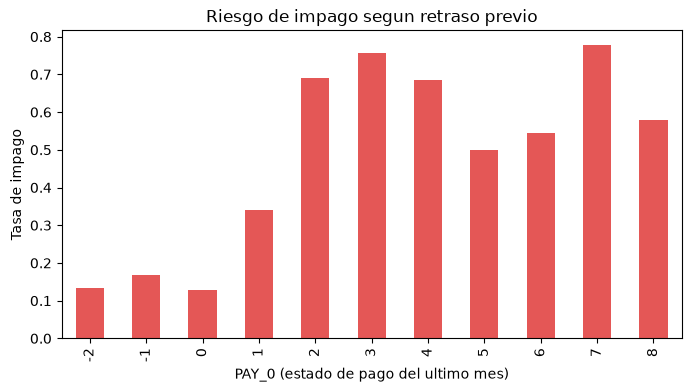

In [4]:
tabla = (
    pd.crosstab(X["PAY_0"], y, normalize="index")
    .rename(columns={0: "pago", 1: "impago"})
)
tabla["n"] = X["PAY_0"].value_counts().sort_index()
display(tabla.head(10))

fig, ax = plt.subplots()
tabla["impago"].dropna().plot(kind="bar", ax=ax, color="#e45756")
ax.set_xlabel("PAY_0 (estado de pago del ultimo mes)")
ax.set_ylabel("Tasa de impago")
ax.set_title("Riesgo de impago segun retraso previo")
plt.show()

## 4. Importes, duplicados y valores atípicos

`LIMIT_BAL` es el crédito concedido; `BILL_AMT1..6` son importes facturados; `PAY_AMT1..6` son pagos realizados. Algunos importes pueden ser negativos (saldo a favor). Comprobemos si hay valores imposibles o filas repetidas antes de decidir el preprocesamiento.

In [5]:
amt_cols = (
    ["LIMIT_BAL"]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
)
display(X[amt_cols].describe().T[["min", "50%", "max"]])

negativos = (X[amt_cols] < 0).sum()
print("Valores negativos por columna de importe:")
print(negativos[negativos > 0].to_string() if negativos.any() else " Ninguno")

df = pd.concat([X, y.rename("default")], axis=1)
print(f"\nFilas duplicadas: {df.duplicated().sum()}")
print(f"Valores faltantes: {int(X.isna().sum().sum())}")

,min,50%,max
LIMIT_BAL,10000.0,140000.0,1000000.0
BILL_AMT1,-165580.0,22381.5,964511.0
BILL_AMT2,-69777.0,21200.0,983931.0
BILL_AMT3,-157264.0,20088.5,1664089.0
BILL_AMT4,-170000.0,19052.0,891586.0
BILL_AMT5,-81334.0,18104.5,927171.0
BILL_AMT6,-339603.0,17071.0,961664.0
PAY_AMT1,0.0,2100.0,873552.0
PAY_AMT2,0.0,2009.0,1684259.0
PAY_AMT3,0.0,1800.0,896040.0


Valores negativos por columna de importe:
BILL_AMT1    590
BILL_AMT2    669
BILL_AMT3    655
BILL_AMT4    675
BILL_AMT5    655
BILL_AMT6    688

Filas duplicadas: 35
Valores faltantes: 0


## 5. Decisiones que llevamos al Módulo 1

| Observación | Consecuencia en el pipeline |
|---|---|
| 30 000 filas, 23 predictoras, sin nulos | No hace falta imputación, pero dejaremos el paso por robustez |
| Clase minoritaria (~22 %) | Estratificar y usar F1 / AUC-PR; probar `class_weight="balanced"` |
| Variables con códigos (`SEX`, `EDUCATION`, `MARRIAGE`, `PAY_*`) | *One-Hot Encoding*; no escalado como numéricas |
| Importes con escalas muy distintas | `StandardScaler` para SVM y regresión logística |
| Duplicados y negativos revisados | Documentar en el informe; no eliminamos negativos sin justificación |

Fijamos ya la división entrenamiento/prueba con semilla para que todos los notebooks sean reproducibles.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Train:", X_train.shape, "| impago:", f"{y_train.mean():.2%}")
print("Test :", X_test.shape, "| impago:", f"{y_test.mean():.2%}")
print("\nSemilla usada:", RANDOM_STATE)

Train: (24000, 23) | impago: 22.12%
Test : (6000, 23) | impago: 22.12%

Semilla usada: 42


## Siguiente paso

`02_modelado_ml.ipynb`: construiremos el `ColumnTransformer`, compararemos dos modelos supervisados y evaluaremos con validación cruzada estratificada. Allí veremos por primera vez por qué el **F1** manda en este problema.

> **Registro ético:** la estructura y las explicaciones de este notebook fueron apoyadas por un asistente de IA generativa. Se declarará en el informe, conforme a las orientaciones del TC; el análisis técnico final es responsabilidad del equipo.